# Módulo 4 — Autocovariância, ACF e PACF

## Seção 1 — Função de autocovariância: definição, propriedades e exemplos teóricos

**Estado:** versão didática para revisão. **Pré-requisitos:** esperança, variância, covariância (Módulo 1), estacionariedade fraca (Módulo 1), ruído branco e passeios aleatórios (Módulos 1–3), operadores de atraso (Módulo 3). **Método:** intuição → formalização → deduções → exemplos → Python → interpretação → exercícios.

**Referência principal conferida.** Morettin e Toloi, *Análise de Séries Temporais: modelos lineares univariados*, v. 1, 3ª ed., **§2.5, pp. 31–33 (páginas 50–52 do PDF do projeto)**: Proposição 2.1, propriedades de simetria, limitação por $\gamma(0)$, não negatividade definida e definição de autocorrelação, equações (2.13)–(2.14). A discussão de autocovariância amostral em §2.5, p. 34 (página 53 do PDF) é apenas contextualizada; a estimação formal será desenvolvida na seção posterior deste módulo. O mapeamento das videoaulas identifica a *Aula 3 — Parte I: Média, autocovariância e autocorrelação teórica* e o Bloco D de ACF/PACF. **Os exemplos de MA(1)/AR(1), a matriz numérica, a demonstração detalhada e os códigos abaixo são complementações didáticas próprias**, compatíveis com as definições, e não exemplos atribuídos literalmente ao livro.

### Objetivos de aprendizagem

Você deverá distinguir autocovariância de covariância entre variáveis genéricas; relacionar estacionariedade fraca e dependência por defasagem; demonstrar as propriedades fundamentais de $\gamma(h)$; compreender o requisito de não negatividade definida; calcular autocovariâncias em ruído branco, MA(1) e AR(1); estimar covariâncias entre trajetórias simuladas sem confundir média de ensemble e média temporal; interpretar limitações desses resumos de segunda ordem.

### 1. Motivação: valores do mesmo processo podem depender uns dos outros

Na estatística elementar, a covariância entre duas variáveis aleatórias reais $X$ e $Y$ é

$$
\mathrm{Cov}(X,Y)=E[(X-E[X])(Y-E[Y])],
$$

quando os segundos momentos existem. Em séries temporais, frequentemente comparamos **o processo consigo mesmo** em dois instantes: $Z_t$ e $Z_{t+h}$.

É natural perguntar: se $Z_t$ ficou acima de sua média, $Z_{t+1}$ tende a ficar acima ou abaixo da própria média? Há associação linear entre observações distantes quatro instantes? A resposta pode ser resumida pela **função de autocovariância**.

Por exemplo, em um processo de temperatura diária, observações próximas podem apresentar covariância positiva; porém, a existência de autocovariância positiva não determina causalidade nem exclui influência sazonal ou tendências ainda não modeladas.

### 2. Definição antes e depois da estacionariedade

Para um processo de segunda ordem com média $\mu(t)=E[Z_t]$, definimos

$$
\gamma(s,t)=\mathrm{Cov}(Z_s,Z_t)
=E[(Z_s-\mu(s))(Z_t-\mu(t))].
$$

A função possui **dois instantes** como argumentos; um processo não estacionário pode apresentar $\gamma(s,t)$ dependente de ambos.

Se $Z_t$ é **fracamente estacionário**, então $\mu(t)=\mu$ é constante e, por definição,

$$
\mathrm{Cov}(Z_t,Z_{t+h})=\gamma(h),
$$

para qualquer deslocamento admissível. A *defasagem* $h$ é a separação temporal orientada entre as observações. Para processos reais, $\gamma(-h)=\gamma(h)$; por isso, alguns livros escrevem $\gamma(|h|)$.

**Notação adotada:**

| Símbolo | Significado |
|---|---|
| $Z_t$ | variável aleatória do processo no instante $t$ |
| $\mu$ | média constante, sob estacionariedade fraca |
| $\gamma(h)$ | autocovariância teórica na defasagem $h$ |
| $\gamma(0)$ | variância do processo |
| $\rho(h)$ | autocorrelação teórica, definida mais adiante |
| $z_t$ | valor observado em uma realização |
| $M$ | número de trajetórias simuladas |
| $N$ | número de instantes em cada trajetória |

A escolha de $\gamma(h)$ para a autocovariância teórica será mantida ao longo do módulo; estimadores amostrais receberão chapéu, como $\widehat\gamma(h)$.

### 3. Primeira propriedade: autocovariância na origem é variância

Na defasagem zero, as duas variáveis são a mesma:

$$
\begin{aligned}
\gamma(0)
&=\mathrm{Cov}(Z_t,Z_t)\\
&=E[(Z_t-\mu)^2]\\
&=\mathrm{Var}(Z_t)\ge0.
\end{aligned}
$$

Essa identidade é útil para verificar cálculos: se um desenvolvimento fornecer $\gamma(0)<0$, algo está errado. Não confunda $\gamma(0)$ com a variância amostral de uma única trajetória.

### 4. Segunda propriedade: simetria das autocovariâncias

Pela simetria da covariância,

$$
\begin{aligned}
\gamma(-h)
&=\mathrm{Cov}(Z_t,Z_{t-h})\\
&=\mathrm{Cov}(Z_{t-h},Z_t)\\
&=\gamma(h).
\end{aligned}
$$

Na última igualdade, usamos estacionariedade fraca: a covariância depende somente da distância temporal, não da posição absoluta do par.

**Interpretação:** o sinal de $\gamma(h)$ não diz que “o futuro causa o passado”. A simetria é uma propriedade algébrica de segunda ordem, não de causalidade temporal.

### 5. Terceira propriedade: limite absoluto

Pela desigualdade de Cauchy–Schwarz aplicada às variáveis centradas,

$$
\bigl|E[(Z_t-\mu)(Z_{t+h}-\mu)]\bigr|
\le\sqrt{E[(Z_t-\mu)^2]E[(Z_{t+h}-\mu)^2]}.
$$

Sob estacionariedade fraca, ambas as variâncias são $\gamma(0)$; logo,

$$
\boxed{|\gamma(h)|\le\gamma(0).}
$$

Se a variância for positiva, podemos normalizar por $\gamma(0)$:

$$
\rho(h)=\frac{\gamma(h)}{\gamma(0)},\qquad\gamma(0)>0.
$$

Portanto,

$$
\rho(0)=1,\qquad |\rho(h)|\le1.
$$

A função $\rho(h)$ é a **função de autocorrelação teórica (ACF)**. Introduzimo-la aqui apenas como consequência da autocovariância; seus estimadores, bandas de incerteza e diagnósticos serão tratados em seções posteriores. Se $\gamma(0)=0$, o processo é degenerado em segunda ordem e a razão $\gamma(h)/\gamma(0)$ não está definida.

### 6. Quarta propriedade: não negatividade definida

Não é suficiente escrever uma lista arbitrária de números que obedece à simetria e ao limite absoluto. Uma função candidata precisa ser compatível com **matrizes de covariância válidas**.

Considere instantes $t_1,\ldots,t_n$ e números reais $a_1,\ldots,a_n$. Defina a combinação linear centrada

$$
Y=\sum_{j=1}^{n}a_j(Z_{t_j}-\mu).
$$

Como toda variância é não negativa,

$$
\mathrm{Var}(Y)\ge0.
$$

Expandindo pela bilinearidade da covariância,

$$
\begin{aligned}
\mathrm{Var}(Y)
&=\sum_{j=1}^{n}\sum_{k=1}^{n}
 a_j a_k\,\mathrm{Cov}(Z_{t_j},Z_{t_k})\\
&=\sum_{j=1}^{n}\sum_{k=1}^{n}
 a_j a_k\,\gamma(t_k-t_j)\ge0.
\end{aligned}
$$

Portanto,

$$
\boxed{\sum_{j=1}^{n}\sum_{k=1}^{n}a_ja_k\gamma(t_k-t_j)\ge0.}
$$

Essa é a **não negatividade definida** descrita na Proposição 2.1 do livro. Em notação matricial, se $\mathbf a=(a_1,\ldots,a_n)^\top$ e $\Gamma_{jk}=\gamma(t_k-t_j)$, então

$$
\mathbf a^\top\Gamma\mathbf a\ge0.
$$

**Por que importa?** Porque garante, entre outras coisas, que a variância de toda combinação linear das observações seja não negativa. Um conjunto de autocovariâncias que viola essa condição não corresponde a uma estrutura de covariância admissível de um processo estacionário real.

#### 6.1 Estrutura de Toeplitz

Para instantes equiespaçados $t,t+1,\ldots,t+n-1$, a matriz é

$$
\Gamma_n=
\begin{pmatrix}
\gamma(0)&\gamma(1)&\cdots&\gamma(n-1)\\
\gamma(1)&\gamma(0)&\cdots&\gamma(n-2)\\
\vdots&\vdots&\ddots&\vdots\\
\gamma(n-1)&\gamma(n-2)&\cdots&\gamma(0)
\end{pmatrix}.
$$

As diagonais paralelas à diagonal principal são constantes; chamamos essa estrutura de **Toeplitz**. Note que uma matriz de covariância pode ser semidefinida positiva sem ser estritamente definida positiva; variáveis linearmente dependentes podem produzir autovalores iguais a zero.

#### 6.2 Exemplo numérico resolvido

Tome a sequência de autocovariâncias $\gamma(0)=1$, $\gamma(1)=1/2$ e $\gamma(2)=1/4$. Para três instantes,

$$
\Gamma_3=
\begin{pmatrix}
1&1/2&1/4\\
1/2&1&1/2\\
1/4&1/2&1
\end{pmatrix}.
$$

Para $\mathbf a=(1,-1,0)^\top$, temos

$$
\begin{aligned}
\mathbf a^\top\Gamma_3\mathbf a
&=1+1-2\left(\frac12\right)\\
&=1\ge0.
\end{aligned}
$$

Esse único cálculo **não prova** a não negatividade definida da matriz para todos os vetores. Para verificar toda a matriz, podemos analisar seus autovalores. Numericamente, eles são aproximadamente $0{,}4069$, $0{,}7500$ e $1{,}8431$, todos positivos. Mais profundamente, a sequência $\gamma(h)=0{,}5^{|h|}$ é uma autocovariância válida de um AR(1) com parâmetros adequados, como veremos adiante.

### 7. Exemplo 1 — Ruído branco

Se $\varepsilon_t$ é ruído branco com média zero e variância $\sigma^2>0$, então

$$
\boxed{\gamma_{\varepsilon}(h)=
\begin{cases}
\sigma^2,&h=0,\\
0,&h\ne0.
\end{cases}}
$$

Isso não significa que os valores precisem ser independentes: ruído branco no sentido de segunda ordem exige ausência de covariância para instantes distintos, não independência completa. A normalidade tampouco decorre da definição.

### 8. Exemplo 2 — Processo MA(1)

Considere o processo de média móvel de ordem 1

$$
Z_t=\varepsilon_t+\theta\varepsilon_{t-1},
$$

com $\varepsilon_t$ de média zero, variância $\sigma^2$ e covariâncias nulas em instantes distintos.

A média é zero. Na defasagem zero:

$$
\begin{aligned}
\gamma_Z(0)
&=\mathrm{Var}(\varepsilon_t+\theta\varepsilon_{t-1})\\
&=\sigma^2+\theta^2\sigma^2\\
&=\sigma^2(1+\theta^2).
\end{aligned}
$$

Na defasagem 1:

$$
\begin{aligned}
\gamma_Z(1)
&=\mathrm{Cov}(\varepsilon_t+\theta\varepsilon_{t-1},
                   \varepsilon_{t+1}+\theta\varepsilon_t)\\
&=\theta\mathrm{Var}(\varepsilon_t)\\
&=\theta\sigma^2.
\end{aligned}
$$

Se $|h|\ge2$, os conjuntos de inovações dos dois termos não se sobrepõem, resultando em covariância zero. Assim,

$$
\boxed{\gamma_Z(h)=
\begin{cases}
\sigma^2(1+\theta^2),&h=0,\\
\theta\sigma^2,&|h|=1,\\
0,&|h|\ge2.
\end{cases}}
$$

Para $\theta=0{,}5$ e $\sigma^2=1$, obtemos $\gamma(0)=1{,}25$, $\gamma(1)=0{,}5$ e $\rho(1)=0{,}4$.

**Observação:** MA(1) designa aqui um **modelo estocástico de médias móveis**, não o procedimento de suavização por janela móvel estudado no Módulo 2. Os nomes se parecem, mas os objetos matemáticos são diferentes.

### 9. Exemplo 3 — Processo AR(1) estacionário

Considere uma solução causal estacionária do modelo

$$
Z_t=\phi Z_{t-1}+\varepsilon_t,
\qquad |\phi|<1,
$$

com ruído branco de variância $\sigma^2$ e inovação ortogonal ao passado do processo. Como deduzido no Módulo 3,

$$
\gamma(0)=\frac{\sigma^2}{1-\phi^2}.
$$

Para $h\ge1$,

$$
\begin{aligned}
\gamma(h)
&=\mathrm{Cov}(Z_t,Z_{t+h})\\
&=\mathrm{Cov}(Z_t,\phi Z_{t+h-1}+\varepsilon_{t+h})\\
&=\phi\gamma(h-1),
\end{aligned}
$$

pois a inovação futura é não correlacionada com $Z_t$. Por recorrência,

$$
\boxed{\gamma(h)=\frac{\sigma^2}{1-\phi^2}\phi^{|h|}.}
$$

Para $\phi=0{,}6$ e $\sigma^2=1$:

| Defasagem | Autocovariância teórica |
|---|---:|
| $0$ | $1{,}5625$ |
| $1$ | $0{,}9375$ |
| $2$ | $0{,}5625$ |
| $3$ | $0{,}3375$ |

A autocovariância decai geometricamente. Para $\phi<0$, seu sinal alterna com a defasagem. Não precisamos antecipar agora a análise completa de identificação de modelos ARMA; o exemplo existe para tornar concreta a função $\gamma(h)$.

### 10. Python integrado — teoria e simulação de muitas trajetórias

É necessário separar **estimativa entre trajetórias** e **estimativa ao longo de uma única trajetória**. No código abaixo, simulamos $M=14.000$ trajetórias de cada processo e observamos a covariância entre as **colunas** de uma matriz $M\times N$. Cada coluna corresponde a muitas realizações no mesmo instante. Esta estratégia aproxima a covariância *de ensemble* sem pressupor que médias temporais sejam iguais às esperanças.

`np.random.default_rng` cria um gerador pseudoaleatório reprodutível; `np.mean(..., axis=0)` calcula médias entre linhas para cada instante; `np.mean` sobre o produto centrado estima a covariância entre dois instantes. Para um processo iniciado em zero, descartar observações iniciais de uma simulação AR(1) reduz a influência da condição inicial; isso não substitui a definição matemática de solução estacionária.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261116)
M, N, burn = 14000, 80, 120
phi, theta = 0.6, 0.5

# M trajetórias de inovações gaussianas independentes
z = rng.normal(0, 1, size=(M, N + burn + 1))

# Simulação conceitual de um AR(1), linha por linha no tempo
ar = np.zeros_like(z)
for t in range(1, ar.shape[1]):
    ar[:, t] = phi * ar[:, t - 1] + z[:, t]
ar = ar[:, burn:burn + N]

# Simulação de MA(1): combina inovações atuais e anteriores
ma = z[:, burn + 1:burn + 1 + N] + theta * z[:, burn:burn + N]

# Aproxima Cov(Z_t, Z_{t+h}) por médias entre trajetórias.
# Eixo 0 da matriz: trajetórias. Eixo 1: instantes.
def cov_ensemble(series, t, h):
    x = series[:, t]
    y = series[:, t + h]
    return np.mean((x - x.mean()) * (y - y.mean()))

lags = np.arange(0, 9)
cov_ar = np.array([cov_ensemble(ar, 30, h) for h in lags])
cov_ma = np.array([cov_ensemble(ma, 30, h) for h in lags])

# Fórmulas teóricas demonstradas no texto
teo_ar = phi ** lags / (1 - phi**2)
teo_ma = np.zeros(9)
teo_ma[0] = 1 + theta**2
teo_ma[1] = theta

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, estim, teor, titulo in [
    (axs[0], cov_ar, teo_ar, "AR(1)"),
    (axs[1], cov_ma, teo_ma, "MA(1)")
]:
    ax.plot(lags, teor, "o-", label="Teórica")
    ax.plot(lags, estim, "s--", label="Simulada")
    ax.set(xlabel="Defasagem h", ylabel="Autocovariância", title=titulo)
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Resultado esperado:** a curva do AR(1) decai gradualmente, enquanto a autocovariância teórica do MA(1) zera após $|h|=1$. As estimativas simuladas oscilam ao redor dos valores teóricos.

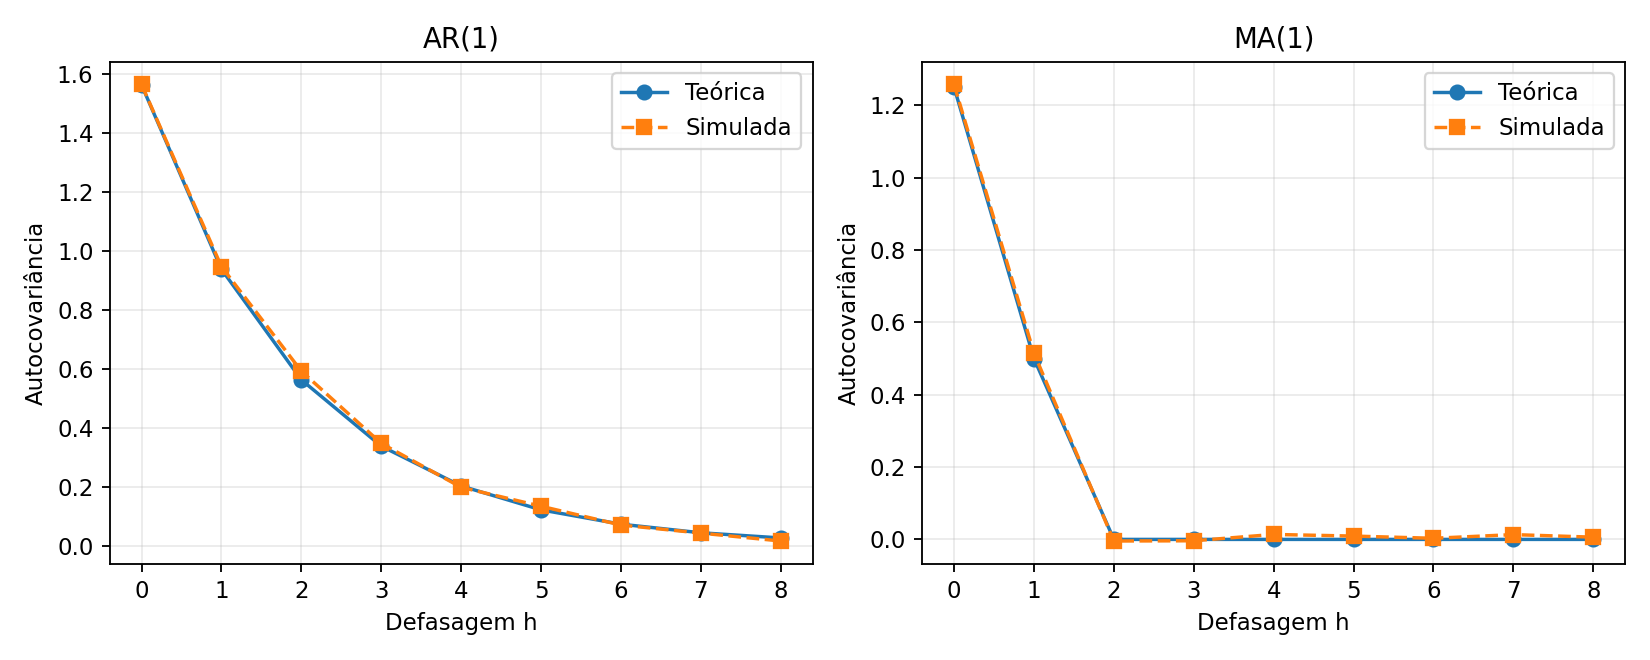

*Figura 1. Comparação de autocovariâncias para AR(1), $\phi=0{,}6$, e MA(1), $\theta=0{,}5$, ambos com variância de inovação igual a 1. As estimativas usam 14.000 trajetórias; pequenas diferenças são naturais. Foram descartados 120 instantes iniciais do AR(1) simulado para reduzir o efeito da inicialização.*

**Verificação executada:** para as defasagens $0,1,2$, o AR(1) apresentou aproximadamente $1{,}5641$, $0{,}9464$, $0{,}5919$, em comparação com $1{,}5625$, $0{,}9375$, $0{,}5625$ teóricos. Para o MA(1), as estimativas foram $1{,}2577$, $0{,}5147$, $-0{,}0044$, comparadas a $1{,}25$, $0{,}5$, $0$ teóricos. Esses valores são **resultados numéricos de simulação**, não identidades exatas.

### 11. Limitações e cuidados interpretativos

A autocovariância mede associação linear de segunda ordem, não toda forma de dependência. Processos distintos podem ter as mesmas autocovariâncias, mas diferentes distribuições conjuntas. Autocovariância zero em defasagens não nulas não implica independência sem hipóteses adicionais. Para processos não fracamente estacionários, uma única função $\gamma(h)$ pode não descrever adequadamente a covariância, pois esta pode depender de $s$ e $t$ separadamente. A estimação a partir de **uma única trajetória observada** também requer cuidados adicionais, pois dependerá das propriedades do processo, do comprimento da série e da convenção do estimador; esses assuntos serão tratados nas seções seguintes.

A propriedade $\gamma(h)\to0$ para $|h|\to\infty$ ocorre em muitos processos usuais de memória curta, mas **não é uma consequência necessária da estacionariedade fraca**. Por exemplo, para $Z_t=U$ com $\mathrm{Var}(U)>0$, temos $\gamma(h)=\mathrm{Var}(U)$ para todo $h$. Esse contraexemplo impede generalizações indevidas.

### 12. Exercícios graduais

**Conceituais.** (1) Por que $\gamma(s,t)$ tem dois índices antes da hipótese de estacionariedade fraca? (2) Explique por que $\gamma(-h)=\gamma(h)$ não demonstra ausência de direção causal. (3) Uma ACF zero em todas as defasagens positivas prova independência? Justifique.

**Matemáticos.** (4) Demonstre a desigualdade $|\gamma(h)|\le\gamma(0)$ por Cauchy–Schwarz. (5) Para um MA(1) com $\theta=-0{,}4$ e $\sigma^2=2$, encontre $\gamma(0)$, $\gamma(1)$ e $\rho(1)$. (6) Para um AR(1) causal com $\phi=-0{,}5$ e $\sigma^2=3$, calcule $\gamma(0)$, $\gamma(1)$ e $\gamma(2)$. (7) Mostre que a matriz de covariância de $(Z_t,Z_{t+1})$ é semidefinida positiva usando a variância de $aZ_t+bZ_{t+1}$.

**Computacionais.** (8) Altere $M$ de 14.000 para 200 e 2.000; registre a oscilação das estimativas. (9) Substitua $\phi=0{,}6$ por $\phi=-0{,}6$; confronte o gráfico com a fórmula teórica. (10) Verifique, com `np.linalg.eigvalsh`, que a matriz $\Gamma_3$ do exemplo numérico tem autovalores não negativos.

**Respostas selecionadas:** (5) $\gamma(0)=2(1+0{,}16)=2{,}32$; $\gamma(1)=-0{,}8$; $\rho(1)\approx-0{,}3448$. (6) $\gamma(0)=3/(1-0{,}25)=4$; $\gamma(1)=-2$; $\gamma(2)=1$. A solução completa dos demais itens ficará como atividade orientada.

### 13. Síntese e referências

A autocovariância de um processo fracamente estacionário depende apenas da defasagem. Sua função precisa ser simétrica, limitada em módulo por $\gamma(0)$ e não negativa definida. As autocovariâncias de ruído branco, MA(1) e AR(1) ilustram estruturas distintas. Simulações podem aproximar seus valores, mas não substituem as demonstrações.

**Referência acadêmica efetivamente consultada:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed., v. 1. São Paulo: Blucher, 2018, §2.5, pp. 31–34, com conferência visual das páginas PDF 50–53. **Complementações didáticas originais:** provas detalhadas, exemplos de MA(1) e AR(1), matriz numérica e códigos. **Mapa audiovisual:** `mapeamento-conteudos-series-temporais.md`, *Aula 3 — Parte I* e Bloco D. A continuidade natural será o estudo de **estimadores amostrais de autocovariância e ACF**, preservando a distinção entre teoria e estimativa.